# Kanz | كنز — EDA

Goal:
* Explore the data and find the numbers that support our story.

Our story = 5 questions (one per app tab):
```
1 Why care?                      -> the ocean is mostly unknown
2 Where is the treasure?         -> Discover
3 What threatens it?             -> Danger (heat -> bleaching, coral -> fish)
4 Where will we lose it first?   -> At Risk (today's heat + Red Sea)
5 What can we do?                -> Dive & Act (dive sites + rare species)
```

Who does what:
```
Member 1 -> Task 1, Task 2   (Discover)
Member 2 -> Task 3, Task 4   (Danger)
Member 3 -> Task 5, Task 6   (At Risk)
Member 4 -> Task 7           (Dive & Act)
Everyone -> Task 8           (summary)
```

Rules:
* Write the real numbers in every answer (they go to the slides and `docs/decisions.md`)
* Read `Kanz_Build_Plan.md` first → section 2 "Data traps" (important notes about the data)

In [1]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# works inside the project (notebooks/) and inside the shared zip folder
DATA = "../datasets_csv/" if os.path.exists("../datasets_csv") else "datasets_csv/"

# Load the data

All 10 files are loaded here, so the tasks can start directly.

In [2]:
# the 3 biggest files are compressed (.csv.gz) -> pandas reads them the same way

# coral bleaching: missing values are written as "nd"
bleaching = pd.read_csv(DATA + "coral_bleaching_surveys.csv.gz", na_values=["nd"], low_memory=False)

# NOAA reef heat stress
stations = pd.read_csv(DATA + "noaa_reef_stations.csv")
heat = pd.read_csv(DATA + "noaa_reef_heat_stress_daily.csv.gz")

# Reef Life Survey
surveys = pd.read_csv(DATA + "reef_life_surveys.csv")
sites = pd.read_csv(DATA + "reef_life_sites.csv")

# OBIS
animals = pd.read_csv(DATA + "obis_marine_animal_species.csv.gz", low_memory=False)
grid = pd.read_csv(DATA + "ocean_grid_cells.csv")
threatened = pd.read_csv(DATA + "threatened_species_near_dive_sites.csv")

# deep-sea corals + sea temperature trend
corals = pd.read_csv(DATA + "deep_sea_corals_species.csv")
sst_trend = pd.read_csv(DATA + "sea_temperature_anomaly.csv")

In [3]:
# quick overview of every table
tables = {"bleaching": bleaching, "stations": stations, "heat": heat, "surveys": surveys, "sites": sites,
          "animals": animals, "grid": grid, "threatened": threatened,
          "corals": corals, "sst_trend": sst_trend}

overview = pd.DataFrame({
    "rows": [len(df) for df in tables.values()],
    "columns": [df.shape[1] for df in tables.values()],
    "missing %": [round(df.isna().mean().mean() * 100, 1) for df in tables.values()],
}, index=tables.keys())

overview

,rows,columns,missing %
bleaching,41361,62,8.6
stations,214,4,0.0
heat,156220,11,0.0
surveys,36447,9,11.8
sites,4894,12,0.0
animals,164232,11,10.0
grid,1881,12,0.5
threatened,5019,5,0.0
corals,4384,8,8.2
sst_trend,531,6,0.0


In [4]:
bleaching.head()

,Site_ID,Sample_ID,Data_Source,Latitude_Degrees,Longitude_Degrees,Ocean_Name,Reef_ID,Realm_Name,Ecoregion_Name,Country_Name,...,TSA_FrequencyMax,TSA_FrequencyMean,TSA_DHW,TSA_DHW_Standard_Deviation,TSA_DHWMax,TSA_DHWMean,Date,Site_Comments,Sample_Comments,Bleaching_Comments
0,2501,10324336,Donner,23.163,-82.5260,Atlantic,NaN,Tropical Atlantic,Cuba and Cayman Islands,Cuba,...,5.0,0.0,0.00,0.74,7.25,0.18,2005-09-15,NaN,NaN,NaN
1,3467,10324754,Donner,-17.575,-149.7833,Pacific,NaN,Eastern Indo-Pacific,Society Islands French Polynesia,French Polynesia,...,4.0,0.0,0.26,0.67,4.65,0.19,1991-03-15,The bleaching does not appear to have gained ...,The bleaching does not appear to have gained ...,NaN
2,1794,10323866,Donner,18.369,-64.5640,Atlantic,NaN,Tropical Atlantic,Hispaniola Puerto Rico and Lesser Antilles,United Kingdom,...,7.0,0.0,0.00,1.04,11.66,0.26,2006-01-15,NaN,NaN,NaN
3,8647,10328028,Donner,17.760,-64.5680,Atlantic,NaN,Tropical Atlantic,Hispaniola Puerto Rico and Lesser Antilles,United States,...,4.0,0.0,0.00,0.75,5.64,0.20,2006-04-15,NaN,NaN,NaN
4,8648,10328029,Donner,17.769,-64.5830,Atlantic,NaN,Tropical Atlantic,Hispaniola Puerto Rico and Lesser Antilles,United States,...,5.0,0.0,0.00,0.92,6.89,0.25,2006-04-15,NaN,NaN,NaN


In [5]:
surveys.head()

,survey_id,site_code,survey_date,depth,visibility,fish_species,fish_count,fish_biomass,hard_coral_pct
0,1003253,USWC1,2010-07-31,9.0,NaN,8,323,6274.6159,1.0
1,1003254,USWC2,2010-08-16,5.4,NaN,13,146,10759.2408,0.0
2,1003255,USWC3,2010-08-17,11.1,NaN,11,93,13458.6650,1.0
3,1003256,USWC4,2010-08-18,11.1,NaN,10,97,14273.7468,1.0
4,1003257,USWC5,2010-08-19,13.5,NaN,15,153,4541.9844,0.0


In [6]:
grid.head()

,cell_lat,cell_lon,ocean_frac,shelf_frac,depth_mean,depth_max,sst_mean,sst_min,sst_max,sst_range,obis_records,obis_species
0,-80,-180,0.96,0.20,432.500000,697,-0.661721,-1.771484,-0.191777,1.579707,6289,509
1,-80,-175,0.84,0.24,401.857143,663,-0.937450,-1.761230,-0.403809,1.357422,4935,376
2,-80,-170,0.72,0.08,515.500000,1034,-0.901418,-1.772461,-0.489258,1.283203,5061,213
3,-80,-165,0.64,0.00,999.437500,2868,-0.887699,-1.768555,-0.503906,1.264648,4787,234
4,-80,-160,0.52,0.04,1585.615385,4225,-0.908583,-1.740234,-0.490362,1.249873,3291,132


---
#  PART 1 — DISCOVER (Member 1)

# Task 1.1 — Discovery curve

Are we still discovering new ocean animals?

* Keep only species: `taxonRank == "Species"`
* Get the year from `scientificNameAuthorship` (example: "(Linnaeus, 1758)" → 1758)
* Count species per decade and plot a bar chart

Hint:
```
animals["year"] = animals["scientificNameAuthorship"].str.extract(r"(1[789]\d\d|20\d\d)").astype(float)
decade = animals["year"] // 10 * 10
```

In [7]:
#Task 1.1 - discovery curve

#1- keep only species
species = animals[animals["taxonRank"] == "Species"].copy()

print("All rows:", len(animals))
print("Species only:", len(species))

#2- get the year from the author text
species["year"] = species["scientificNameAuthorship"].str.extract(r"(1[789]\d\d|20\d\d)").astype(float)

#how many species have no year? (missing values)
print("\nSpecies with no year:", species["year"].isna().sum())

#3- turn the year into a decade
species["decade"] = species["year"] // 10 * 10

#4- count species per decade
per_decade = species["decade"].value_counts().sort_index()
print(per_decade.tail(8))

All rows: 164232
Species only: 142221

Species with no year: 190
decade
1950.0     6048
1960.0     6945
1970.0     8862
1980.0    10364
1990.0     9887
2000.0    10230
2010.0     8896
2020.0     4166
Name: count, dtype: int64


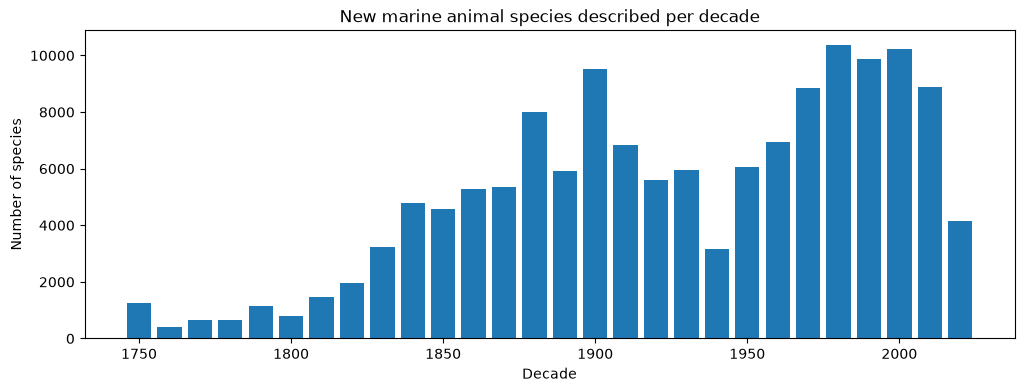

In [8]:
# 5- bar chart
plt.figure(figsize=(12, 4))
plt.bar(per_decade.index, per_decade.values, width=8)
plt.title("New marine animal species described per decade")
plt.xlabel("Decade")
plt.ylabel("Number of species")
plt.show()

**What did you learn? (2–3 lines with numbers)**

Answer:
* We are still discovering ocean animals: about 9,000–10,000 new species were described in each decade from 1980 to 2010 (10,364 in the 1980s, 8,896 in the 2010s).
* The curve has not flattened, so the ocean still hides many species we have not found yet.
* The 2020s look lower (4,166) only because the decade is not finished. 190 species had no year in the text and were left out.

# Task 1.2 — Rare and deep treasures

* What % of species were recorded only **once** (`records == 1`)?
* In `corals` (deep-sea corals and sponges): the 10 deepest species (`max_depth_m`)
* How many species are deeper than 1,000 m, and how many have a photo (`ImageURL` not empty)?

In [9]:
#Task 1.2 — Rare and deep treasures

#1- species recorded only once
seen_once = species[species["records"] == 1]

print("Species seen only once:", len(seen_once))
print("Percent:", round(len(seen_once) / len(species) * 100, 1), "%")

Species seen only once: 26936
Percent: 18.9 %


In [10]:
#2- the 10 deepest species
deepest = corals.sort_values("max_depth_m", ascending=False).head(10)

print("\n10 deepest species:")
deepest[["ScientificName", "VernacularNameCategory", "Ocean", "max_depth_m"]]


10 deepest species:


,ScientificName,VernacularNameCategory,Ocean,max_depth_m
0,Umbellula,sea pen,North Atlantic,6369.0
1,Umbellula magniflora,sea pen,South Atlantic,5895.0
2,Cladorhizidae,demosponge,North Pacific,5894.0
3,Porifera,sponge (unspecified),South Pacific,5855.0
4,Caulophacus,glass sponge,South Pacific,5853.0
5,Asbestopluma,demosponge,South Pacific,5852.0
6,Conopora verrucosa,lace coral,South Atlantic,5845.0
7,Abyssocladia marianensis,demosponge,North Pacific,5816.0
8,Abyssopathes lyra,black coral,South Pacific,5772.0
9,Hyalostylus,glass sponge,South Pacific,5771.0


In [11]:
#3- deeper than 1,000 m and how many have a photo
deep = corals[corals["max_depth_m"] > 1000]
with_photo = corals[corals["ImageURL"].notna()]
deep_with_photo = deep[deep["ImageURL"].notna()]

print("All deep-sea species:", len(corals))
print("Deeper than 1,000 m:", len(deep))
print("Have a photo:", len(with_photo), "(", round(len(with_photo) / len(corals) * 100, 1), "% )")
print("Deeper than 1,000 m AND have a photo:", len(deep_with_photo))

All deep-sea species: 4384
Deeper than 1,000 m: 1446
Have a photo: 1522 ( 34.7 % )
Deeper than 1,000 m AND have a photo: 748


**What did you learn? (2–3 lines with numbers)**

Answer:
* Many species are barely known: 26,936 species (18.9%) were recorded only once in history.
* Life reaches extreme depths: the deepest is a sea pen at 6,369 m, and 1,446 deep-sea coral / sponge species live below 1,000 m (no sunlight).
* Only 1,522 of 4,384 (34.7%) have a photo in the NOAA database, so about 2 out of 3 deep-sea species have no photo at all.

# Task 2.1 — More sampling = more species?

Each row of `grid` is a 5° × 5° ocean cell.

* Scatter plot: log(`obis_records`) vs log(`obis_species`)
* Correlation between them

Hint:
```
np.log1p(grid["obis_records"])
```

In [12]:
#Task 2.1 — More sampling = more species?

#1- log because the numbers are very spread out (1 -> 25 million)
log_records = np.log1p(grid["obis_records"])
log_species = np.log1p(grid["obis_species"])

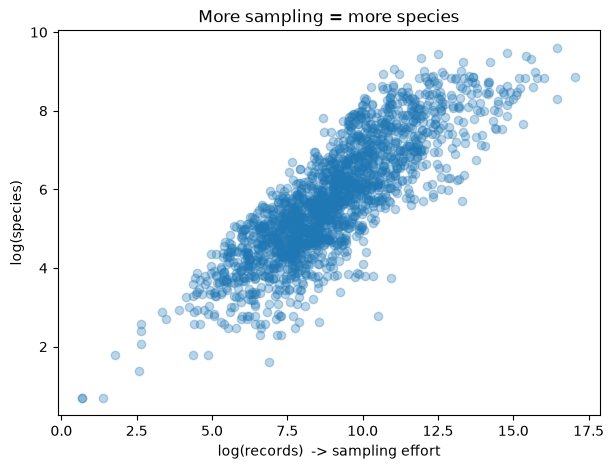

In [13]:
#2- scatter plot: each dot is one ocean cell
plt.figure(figsize=(7, 5))
plt.scatter(log_records, log_species, alpha=0.3)
plt.title("More sampling = more species")
plt.xlabel("log(records)  -> sampling effort")
plt.ylabel("log(species)")
plt.show()

In [14]:
#3- correlation (log vs raw)
print("Correlation (log):", round(log_records.corr(log_species), 2))
print("Correlation (raw):", round(grid["obis_records"].corr(grid["obis_species"]), 2))

Correlation (log): 0.83
Correlation (raw): 0.43


**What did you learn? (2–3 lines with numbers)**

Answer:
* More sampling = more species: across 1,881 ocean cells, the correlation between log(records) and log(species) is 0.83 (very strong).
* Without the log it is only 0.43, because records range from 1 to 25 million; the log makes the real relationship visible.
* So a low species count can mean "not searched enough", not "not rich". This is sampling bias, and it is why Model 1 must estimate the expected species, not just count the recorded ones.

# Task 2.2 — Where does life live?

* Species vs sea temperature (`sst_mean`) → scatter or groups (cold / mild / warm)
* Species vs depth (`depth_mean`)
* Map: `plt.scatter(grid["cell_lon"], grid["cell_lat"], c=np.log1p(grid["obis_species"]))`

Question: are the richest cells in warm or cold seas?

In [15]:
#Task 2.2 — Where does life live?

#missing temperature
print("Cells with no temperature:", grid["sst_mean"].isna().sum())

#1- group the cells by sea temperature
grid["temp_group"] = pd.cut(grid["sst_mean"], bins=[-5, 10, 20, 40],
                            labels=["cold (<10)", "mild (10-20)", "warm (>20)"])

#median species and median records in each group
grid.groupby("temp_group", observed=True)[["obis_species", "obis_records"]].median()

Cells with no temperature: 31


,obis_species,obis_records
temp_group,,
cold (<10),169.0,5636.0
mild (10-20),297.0,7260.0
warm (>20),503.0,9545.0


In [16]:
#2- group the cells by depth
grid["depth_group"] = pd.cut(grid["depth_mean"], bins=[-1, 200, 1000, 4000, 20000],
                             labels=["shallow (<200)", "200-1000", "1000-4000", "deep (>4000)"])

grid.groupby("depth_group", observed=True)[["obis_species", "obis_records"]].median()

,obis_species,obis_records
depth_group,,
shallow (<200),366.5,6060.0
200-1000,424.0,10339.0
1000-4000,456.0,13386.0
deep (>4000),162.0,4043.0


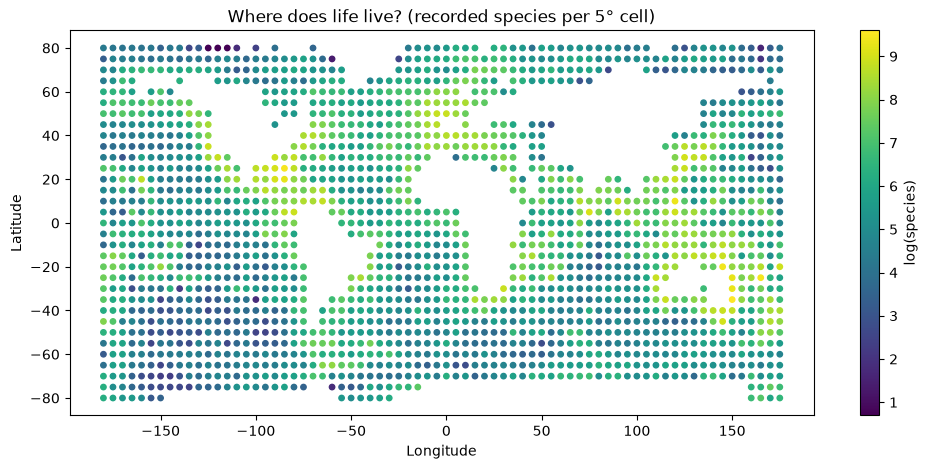

In [17]:
#3- world map: each dot is one ocean cell, color = number of species (log)
plt.figure(figsize=(12, 5))
plt.scatter(grid["cell_lon"], grid["cell_lat"], c=np.log1p(grid["obis_species"]),
            cmap="viridis", s=15)
plt.colorbar(label="log(species)")
plt.title("Where does life live? (recorded species per 5° cell)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**What did you learn? (2–3 lines with numbers)**

Answer:
* Life lives in warm seas: warm cells (>20 °C) have a median of 503 species vs 169 in cold cells (<10 °C), about 3× more, while sampling is only 1.7× higher (9,545 vs 5,636 records). 20 °C ≈ the minimum temperature for coral reefs.
* The deepest cells (>4,000 m) show the fewest species (162) but also the least sampling (4,043 records), so we cannot tell if they are poor or just unexplored (sampling bias).
* The map shows the richest cells along warm coasts (Caribbean, Southeast Asia, eastern Australia) and near well-studied regions (Europe, Japan), while the open South Pacific and the poles are poorest, which mixes real richness with sampling bias.
* 31 cells have no sea temperature.

---
#  PART 2 — DANGER (Member 2)

# Task 3.1 — Data quality check

* How many rows have a bleaching % (`Percent_Bleaching` not missing)?
* How many unique `Sample_ID`? (each sample is repeated once per seabed type)
* How many rows have `ClimSST == 262.15` (fake −11 °C)?
* Missing values per column (bar chart of the top 10)

In [48]:
#Task 3.1 — Data quality check

#1- rows that have a bleaching %
has_bleaching = bleaching["Percent_Bleaching"].notna()
n_all = len(bleaching)
n_bleach = has_bleaching.sum()

print("All rows:", n_all)
print("Rows WITH a bleaching %:", n_bleach, "(", round(n_bleach / n_all * 100, 1), "% )")
print("Rows WITHOUT a bleaching % (missing):", n_all - n_bleach, "(", round((n_all - n_bleach) / n_all * 100, 1), "% )")

#2- unique samples (each sample is repeated once per seabed type)
n_unique = bleaching.loc[has_bleaching, "Sample_ID"].nunique()
print("\nUnique samples (with bleaching %):", n_unique, "(", round(n_unique / n_bleach * 100, 1), "% of the rows with bleaching %)")
print("Repeated rows:", n_bleach - n_unique)

All rows: 41361
Rows WITH a bleaching %: 34515 ( 83.4 % )
Rows WITHOUT a bleaching % (missing): 6846 ( 16.6 % )

Unique samples (with bleaching %): 23271 ( 67.4 % of the rows with bleaching %)
Repeated rows: 11244


In [28]:
#3- fake temperature: ClimSST = 262.15 Kelvin = -11 °C (impossible for a reef)
fake = bleaching["ClimSST"] == 262.15
print("Rows with fake ClimSST:", fake.sum())
print("Percent:", round(fake.mean() * 100, 1), "%")

Rows with fake ClimSST: 7188
Percent: 17.4 %


In [49]:
bleaching.loc[bleaching["ClimSST"] == 262.15, "ClimSST"] = np.nan

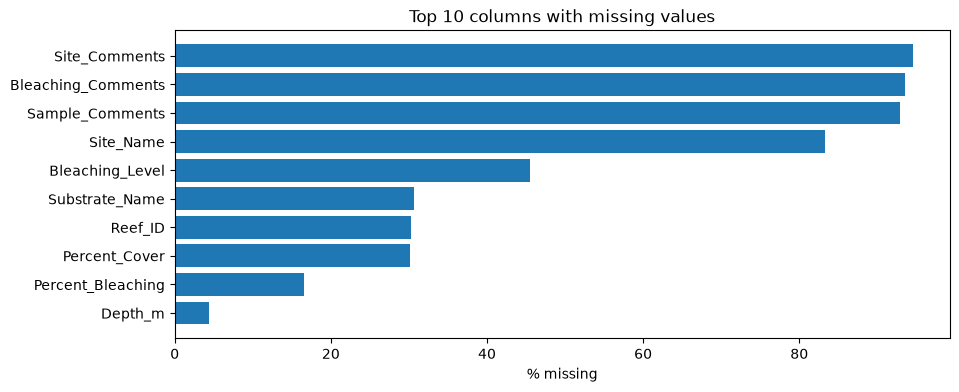

In [38]:
#4- missing values per column (top 10)
missing = (bleaching.isna().mean() * 100).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 4))
plt.barh(missing.index, missing.values)
plt.gca().invert_yaxis()   # biggest on top
plt.title("Top 10 columns with missing values")
plt.xlabel("% missing")
plt.show()

In [50]:
bleaching = bleaching.drop(columns=["Site_Comments", "Bleaching_Comments", "Sample_Comments"])

**What did we learn? (2–3 lines with numbers)**

Answer:
* Only 34,515 of 41,361 rows (83%) have a bleaching %, and they are only 23,271 unique samples (67%), because each sample is repeated once per seabed type with the same bleaching %. We must keep one row per sample, or the model will see the same sample many times.
* 7,188 rows (17.4%) had ClimSST = 262.15 K (−11 °C), which is impossible for a coral reef. We turned it into missing instead of dropping the rows, because the other columns are fine.
* The most missing columns are text comments (Site, Bleaching and Sample comments: over 90% missing), so we dropped them. The target `Percent_Bleaching` is missing in 16.6% of rows, so those rows will be removed in Task 3.2.

# Task 3.2 — Create the target and check balance

Keep one row per sample, then create:
```
0 = none    -> Percent_Bleaching == 0
1 = mild    -> between 0 and 20
2 = severe  -> 20 or more
```
Plot the class balance. Is it balanced?

Hint:
```
df = bleaching[bleaching["Percent_Bleaching"].notna()].drop_duplicates("Sample_ID")
```

In [51]:

#1- keep rows with a bleaching %, one row per sample
df = bleaching[bleaching["Percent_Bleaching"].notna()].drop_duplicates("Sample_ID").copy()
print("Rows before:", len(bleaching))
print("Rows after (one per sample):", len(df))

Rows before: 41361
Rows after (one per sample): 23271


In [60]:
#2- target: 0 none / 1 mild (<20%) / 2 severe (>=20%)
conditions = [
    df["Percent_Bleaching"] == 0,    # none
    df["Percent_Bleaching"] < 20,    # mild
]
df["target"] = np.select(conditions, [0, 1], default=2)   # anything else = severe

df[["Percent_Bleaching", "target"]].head(10)

,Percent_Bleaching,target
0,50.20,2
1,50.70,2
2,50.90,2
3,50.90,2
4,50.90,2
5,51.00,2
6,51.30,2
7,51.38,2
8,51.40,2
9,51.53,2


In [78]:
#3- class balance
counts = df["target"].value_counts().sort_index()
percent = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"count": counts, "percent %": percent}))



        count  percent %
target                  
0        9205       39.6
1        9085       39.0
2        4981       21.4


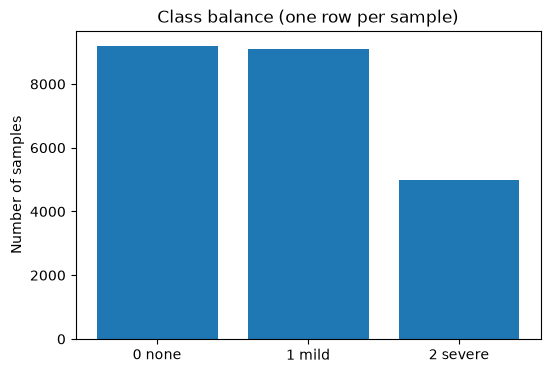

In [88]:
plt.figure(figsize=(6, 4))
plt.bar(["0 none", "1 mild", "2 severe"], counts.values)
plt.title("Class balance (one row per sample)")
plt.ylabel("Number of samples")
plt.show()

**What did we learn? (2–3 lines with numbers)**

Answer:
* After keeping one row per sample, we have 23,271 samples: 39.6% none, 39.0% mild and 21.4% severe. So 60.4% of samples (14,066) show some bleaching (but many surveys were done during heat events, so this is higher than on a normal reef).
* The classes are not balanced: severe (the class we care about most) is about half the size of the others. A model that never predicts severe could still get about 79% accuracy.
* So we will use macro F1 (all classes count equally) and severe recall (how many severe cases we catch), not accuracy.

# Task 3.3 — Heat stress vs bleaching

`TSA_DHW` = heat stress (degree heating weeks).

* Group it: 0 / 0–2 / 2–4 / 4–8 / 8+
* Share of severe bleaching in each group → bar chart
* Correlation heatmap: heat columns (`TSA_DHW`, `SSTA_DHW`, `TSA`, `SSTA`, `Temperature_Maximum`, ...) with `Percent_Bleaching`

Hint:
```
pd.cut(df["TSA_DHW"], bins=[-0.1, 0, 2, 4, 8, 100], labels=["0", "0-2", "2-4", "4-8", "8+"])
```

In [97]:
#Task 3.3 — Heat stress vs bleaching

#1- group the heat stress (DHW)
df["dhw_group"] = pd.cut(df["TSA_DHW"], bins=[-0.1, 0, 2, 4, 8, 100],
                         labels=["0", "0-2", "2-4", "4-8", "8+"])

#2- share of severe bleaching (target == 2) in each group
df["is_severe"] = df["target"] == 2
severe_by_heat = df.groupby("dhw_group", observed=True).agg(
    samples=("is_severe", "size"),
    severe_pct=("is_severe", "mean"))
severe_by_heat["severe_pct"] = (severe_by_heat["severe_pct"] * 100).round(1)
severe_by_heat

,samples,severe_pct
dhw_group,,
0,15060,12.7
0-2,3105,22.4
2-4,2278,37.7
4-8,1997,53.2
8+,764,58.6


In [ ]:
#Task 3.1 — Data quality check

#1- rows that have a bleaching %
has_bleaching = bleaching["Percent_Bleaching"].notna()
n_all = len(bleaching)
n_bleach = has_bleaching.sum()

print("All rows:", n_all)
print("Rows WITH a bleaching %:", n_bleach, "(", round(n_bleach / n_all * 100, 1), "% )")
print("Rows WITHOUT a bleaching % (missing):", n_all - n_bleach, "(", round((n_all - n_bleach) / n_all * 100, 1), "% )")

#2- unique samples (each sample is repeated once per seabed type)
n_unique = bleaching.loc[has_bleaching, "Sample_ID"].nunique()
print("\nUnique samples (with bleaching %):", n_unique, "(", round(n_unique / n_bleach * 100, 1), "% of the rows with bleaching %)")
print("Repeated rows:", n_bleach - n_unique)

All rows: 41361
Rows WITH a bleaching %: 34515 ( 83.4 % )
Rows WITHOUT a bleaching % (missing): 6846 ( 16.6 % )

Unique samples (with bleaching %): 23271 ( 67.4 % of the rows with bleaching %)
Repeated rows: 11244


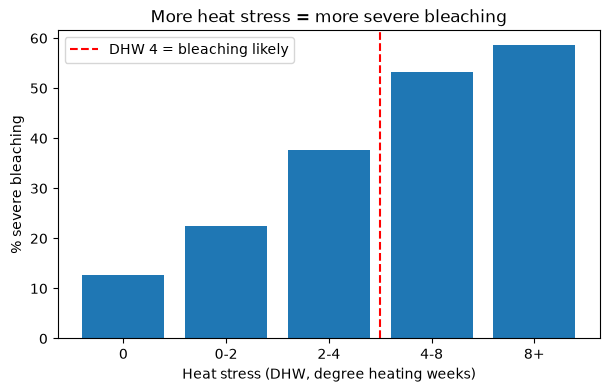

In [105]:
#3- bar chart
plt.figure(figsize=(7, 4))
plt.bar(severe_by_heat.index.astype(str), severe_by_heat["severe_pct"])
plt.axvline(2.5, color="red", linestyle="--", label="DHW 4 = bleaching likely")
plt.title("More heat stress = more severe bleaching")
plt.xlabel("Heat stress (DHW, degree heating weeks)")
plt.ylabel("% severe bleaching")
plt.legend()
plt.show()

**What did you learn? (2–3 lines with numbers)**


Answer:
* The hotter the sea, the more severe bleaching: it rises step by step from 12.7% when there is no heat stress (DHW 0) to 58.6% when the heat stress is very high (DHW 8+), about 4.6× more.
* The very hot group has the fewest samples (764), but the biggest effect: 58.6% of them bleached severely. Strong heat waves are rare, but when they happen, more than half of the corals bleach severely.
* The raw temperature barely matters (Temperature_Maximum r = −0.01): what matters is heat ABOVE the normal for that reef (SSTA_DHW r = 0.28, TSA_DHW r = 0.27). The strongest correlation is only 0.28, so heat alone is not enough → we need a model that combines many columns (Model 2).

# Task 3.4 — Is the ocean warming?

Line chart of `sea_temperature_anomaly_annual` for `entity == "World"` (1850 → today).

In [127]:
#Task 3.4 — Is the ocean warming?

#1- keep the whole world only (the file also has the North and South hemispheres)
world = sst_trend[sst_trend["entity"] == "World"].sort_values("year")

#2- the anomaly at some key years (as a table)
key_years = [1850, 1900, 1950, 1980, 2000, 2010, 2020, 2024]
key_table = world[world["year"].isin(key_years)][["year", "sea_temperature_anomaly_annual"]]
key_table = key_table.rename(columns={"sea_temperature_anomaly_annual": "°C above normal"})
key_table["°C above normal"] = key_table["°C above normal"].round(2)
key_table.reset_index(drop=True)

,year,°C above normal
0,1850,-0.03
1,1900,0.04
2,1950,0.09
3,1980,0.40
4,2000,0.54
5,2010,0.75
6,2020,0.96
7,2024,1.21


**What did we learn? (2–3 lines with numbers)**

Answer:
* Yes, the ocean is warming over time , the world sea surface was about 0 °C above normal in 1850, and 1.21 °C above normal in 2024 (about +1.2 °C). This matches what is known about climate change.
* Most of the warming happened recently only +0.09 °C by 1950, then +1.12 °C after it. Since 1972, no year has been below normal.
* From Task 3.3 we know that heat above normal causes severe bleaching, so a warmer ocean means more bleaching in the future: the hotter the sea, the more the corals bleach.


# Task 4.1 — Does losing coral mean losing fish?

* Merge `surveys` with `sites` on `site_code` (to get `lat_zone`)
* Box plot: fish species per survey by `lat_zone`
* Group `hard_coral_pct`: 0 / 0–10 / 10–30 / 30–50 / 50+ → average `fish_species` per group (bar chart)

In [134]:

#1- merge surveys with sites to get lat_zone
reef = surveys.merge(sites[["site_code", "lat_zone", "country"]], on="site_code", how="left")
print("Surveys:", len(surveys), "| after merge:", len(reef))
print("Surveys with no zone:", reef["lat_zone"].isna().sum())

#how many surveys have a coral %?
print("Surveys with hard coral %:", reef["hard_coral_pct"].notna().sum(),
      f"({reef['hard_coral_pct'].notna().mean() * 100:.1f}%)")

Surveys: 36447 | after merge: 36447
Surveys with no zone: 0
Surveys with hard coral %: 4969 (13.6%)


In [146]:
#2- fish species per survey by zone
print(reef.groupby("lat_zone")["fish_species"].agg(["count", "median", "mean"]).round(1))


           count  median  mean
lat_zone                      
Polar         61     2.0   1.9
Temperate  27488    10.0  12.4
Tropical    8898    42.0  44.2


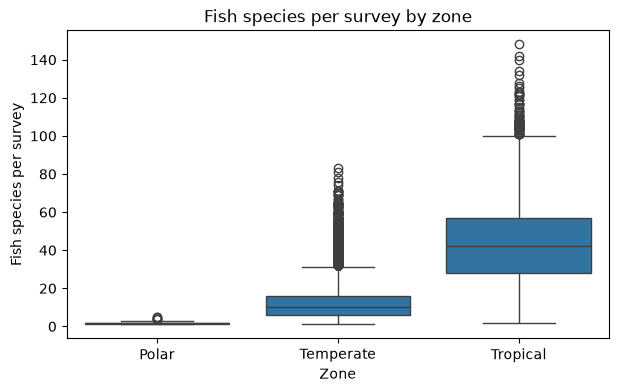

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=reef, x="lat_zone", y="fish_species", order=["Polar", "Temperate", "Tropical"])
plt.title("Fish species per survey by zone")
plt.xlabel("Zone")
plt.ylabel("Fish species per survey")
plt.show()

In [167]:
#3- group hard coral % and get the average fish species per group
reef["coral_group"] = pd.cut(reef["hard_coral_pct"], bins=[-0.1, 0, 10, 30, 50, 100],
                             labels=["0", "0-10", "10-30", "30-50", "50+"])

fish_by_coral = reef.groupby("coral_group", observed=True)["fish_species"].agg(["count", "mean"]).round(1)
fish_by_coral = fish_by_coral.rename(columns={"count": "surveys", "mean": "avg fish species"})
fish_by_coral

,surveys,avg fish species
coral_group,,
0,1251,15.0
0-10,1170,33.0
10-30,1248,44.9
30-50,778,48.8
50+,522,49.4


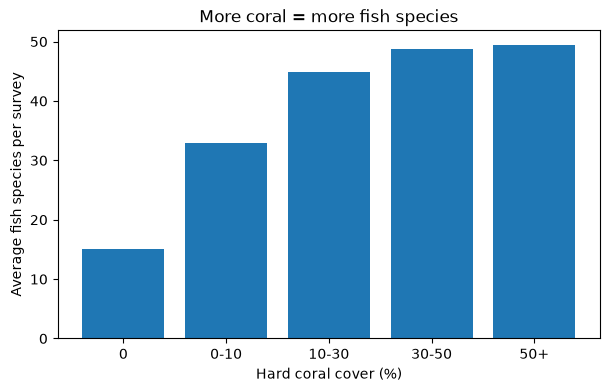

In [169]:
plt.figure(figsize=(7, 4))
plt.bar(fish_by_coral.index.astype(str), fish_by_coral["avg fish species"])
plt.title("More coral = more fish species")
plt.xlabel("Hard coral cover (%)")
plt.ylabel("Average fish species per survey")
plt.show()

In [176]:
#4- correlation (spearman: works well when the relation is not a straight line)
print("Spearman correlation:", round(reef["hard_coral_pct"].corr(reef["fish_species"], method="spearman"), 2))

Spearman correlation: 0.63


**What did we learn? (2–3 lines with numbers)**

Answer:

* Yes, losing coral means losing fish, places with no hard coral have 15 fish species on average, vs 49.4 with 50%+ coral, about 3× more (Spearman r = 0.63), because coral is the home of the fish.
* Warm seas are the richest ,  a median of 42 fish species per survey in tropical waters, vs 10 in temperate and only 2 in polar waters.
* So when heat bleaches and kills the coral (Task 3), the fish lose their home too. Limit , only 4,969 of 36,447 surveys (13.6%) recorded a hard coral %.

---
# ⚠️ PART 3 — AT RISK (Member 3)

# Task 5.1 — Heat stress today





**What is DHW (Degree Heating Weeks)?**

NOAA's measure of heat stress on corals:
* HotSpot = today's sea temperature − the normal temperature of the hottest month in that place
* Only HotSpots of 1 °C or more count (smaller ones do not stress the coral)
* DHW = the sum of these HotSpots over the **last 12 weeks** (unit: °C-weeks)

Example: 2 °C above normal for 4 weeks → DHW = 8.

* DHW ≥ 4 → bleaching likely
* DHW ≥ 8 → severe bleaching likely

So DHW measures both **how hot** and **for how long**, which is why it predicts bleaching better than the temperature itself.

In [ ]:
#Task 5.1 — Heat stress these days

#1- make a date column, sort by date, then take the last day of each station
heat["date"] = pd.to_datetime(heat[["year", "month", "day"]])
today = heat.sort_values("date").groupby("station").tail(1)

print("Stations:", len(today))
print("Last day in the data:", today["date"].max().date())

Stations: 214
Last day in the data: 2026-11-10


In [187]:
#2- how many stations are on bleaching alert?
alert = (today["dhw"] >= 4).sum()
severe = (today["dhw"] >= 8).sum()
print(f"DHW >= 4 (bleaching likely): {alert} of {len(today)} ({alert / len(today) * 100:.1f}%)")
print(f"DHW >= 8 (severe bleaching likely): {severe} of {len(today)} ({severe / len(today) * 100:.1f}%)")

DHW >= 4 (bleaching likely): 72 of 214 (33.6%)
DHW >= 8 (severe bleaching likely): 46 of 214 (21.5%)


In [192]:
#3- top 10 hottest stations today
top10 = today.sort_values("dhw", ascending=False).head(10)[["station", "sst", "sst_anomaly", "dhw"]]
top10.round(2).reset_index(drop=True)

,station,sst,sst_anomaly,dhw
0,Northern Line Islands,29.77,2.34,26.85
1,Southern Line Islands,30.45,2.58,19.04
2,Panama Pacific East,29.59,1.69,18.95
3,Yucatan Peninsula,28.18,1.91,18.11
4,"Galapagos, Ecuador",28.94,6.56,17.91
5,"Jazan, Saudi Arabia",32.04,1.51,17.52
6,Cape Verde Islands,29.24,3.08,17.14
7,Colombia Atlantic,29.99,1.78,17.02
8,Costa Rica Pacific,30.35,2.64,16.41
9,Panama Pacific West,30.00,2.26,15.95


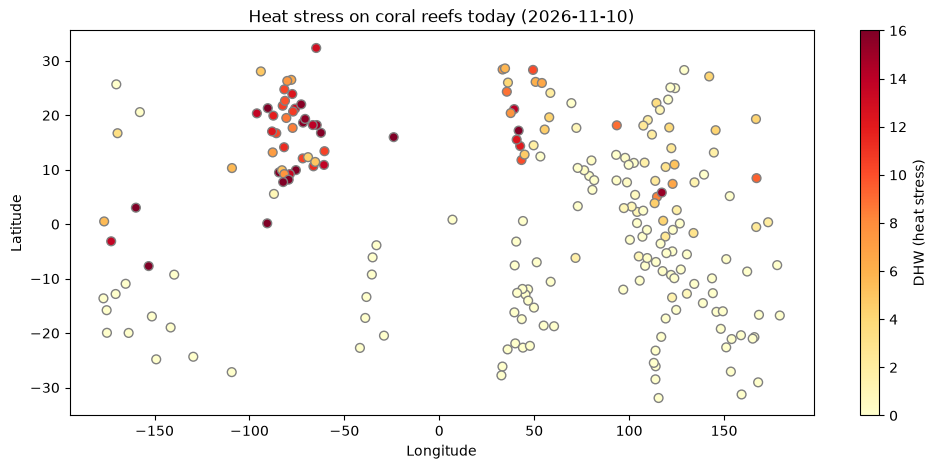

In [ ]:
#4- map: merge with stations (lat / lon), color by dhw
today_map = today.merge(stations, on="station", how="left")

plt.figure(figsize=(12, 5))
plt.scatter(today_map["lon"], today_map["lat"], c=today_map["dhw"],
            cmap="YlOrRd", s=40, edgecolor="gray", vmin=0, vmax=16)
plt.colorbar(label="DHW (heat stress)")
plt.title(f"Heat stress on coral reefs these days ({today['date'].max().date()})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**What did we learn? (2–3 lines with numbers)**

Answer:

* As of 10 Nov 2026, 72 of 214 reef regions (33.6%) are on bleaching alert (DHW ≥ 4). 46 of them (21.5% of all regions) are at the severe level (DHW ≥ 8): so more than half of the regions on alert (46 of 72, 64%) are already at the severe level.
* The region with the highest heat stress is the Northern Line Islands (remote islands in the middle of the Pacific, DHW 26.8), more than 3× the severe level, even though its sea is only 29.8 °C. The map shows the heat stress is concentrated in the Caribbean / Central America, the Red Sea and the central Pacific, while the southern half is calm (it is spring there).
* The hottest seas in the world today are both Saudi: Al Madinah and Makkah (32.2 °C) and Jazan (32.0 °C). Jazan is also 6th in heat stress (DHW 17.5): the danger is happening now, in our own waters.

# Task 5.2 — Heat over time in Saudi waters



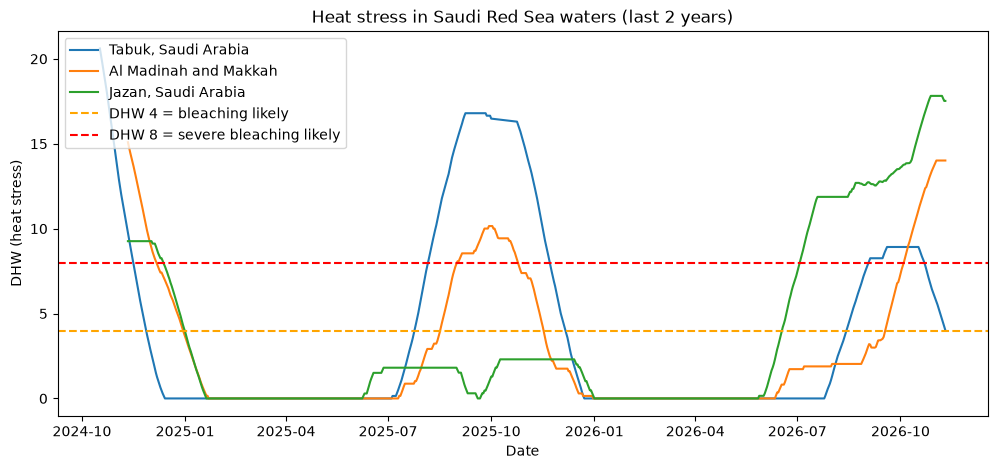

In [202]:
#Task 5.2 — Heat over time in Saudi waters

#1- keep the 3 Saudi stations (north -> south)
saudi = ["Tabuk, Saudi Arabia", "Al Madinah and Makkah", "Jazan, Saudi Arabia"]
saudi_heat = heat[heat["station"].isin(saudi)]

#2- line chart: one line per station
plt.figure(figsize=(12, 5))
for s in saudi:
    one = saudi_heat[saudi_heat["station"] == s]
    plt.plot(one["date"], one["dhw"], label=s)

#3- alert lines
plt.axhline(4, color="orange", linestyle="--", label="DHW 4 = bleaching likely")
plt.axhline(8, color="red", linestyle="--", label="DHW 8 = severe bleaching likely")

plt.title("Heat stress in Saudi Red Sea waters (last 2 years)")
plt.xlabel("Date")
plt.ylabel("DHW (heat stress)")
plt.legend()
plt.show()

In [206]:
#4- summary per station
summary = saudi_heat.groupby("station").agg(
    days=("dhw", "size"),
    days_dhw_4=("dhw", lambda x: (x >= 4).sum()),
    days_dhw_8=("dhw", lambda x: (x >= 8).sum()),
    max_dhw=("dhw", "max"),
    max_sst=("sst", "max"))
summary.loc[saudi].round(1)

,days,days_dhw_4,days_dhw_8,max_dhw,max_sst
station,,,,,
"Tabuk, Saudi Arabia",730,244,167,20.6,32.4
Al Madinah and Makkah,730,196,118,15.1,33.6
"Jazan, Saudi Arabia",730,197,162,17.8,34.4


**What did you learn? (2–3 lines with numbers)**

Answer:
* We compared 3 Saudi reef regions on the Red Sea (Tabuk in the north, Al Madinah and Makkah in the middle, Jazan in the south) from Oct 2024 to Nov 2026. All 3 reached the severe level (DHW ≥ 8): heat stress in our waters comes back every year.
* Jazan has the highest heat stress now: it was calm in 2025 (max DHW 3.9) but reached its highest level in 2026 (17.8), with the hottest sea of the three (34.4 °C).
* Tabuk (north) suffered the longest: it was on bleaching alert (DHW ≥ 4) for 244 days in the last 2 years, more than Jazan (197 days). It also had the strongest heat stress of the 3 regions: DHW 20.6 in Oct 2024, and again 16.8 in Sep 2025.
* The most affected region changes from year to year: in 2024 and 2025 it was Tabuk (north), while Jazan (south) was calm. In 2026 it is Jazan, while Tabuk is calmer. So no part of our Red Sea is safe.


# Task 6.1 — The Red Sea twist

Under strong heat (`TSA_DHW >= 4`), compare the share of **severe** bleaching:
```
Red Sea      -> Ecoregion_Name contains "Red Sea" or "Gulf of Aden"
Rest of world
```
Show the number of surveys for each group too. What does it mean for Saudi reefs?


In [214]:
#Task 6.1 — The Red Sea twist

#1- label each sample: Red Sea or rest of the world
df["region"] = np.where(df["Ecoregion_Name"].str.contains("Red Sea|Gulf of Aden", na=False),
                        "Red Sea", "Rest of world")

#2- keep only samples under strong heat
hot = df[df["TSA_DHW"] >= 4]

#3- compare: number of surveys, number of sites, share of severe bleaching
twist = hot.groupby("region").agg(
    surveys=("target", "size"),
    sites=("Site_ID", "nunique"),
    severe_pct=("target", lambda x: (x == 2).mean() * 100),
    avg_bleaching_pct=("Percent_Bleaching", "mean"))
twist.round(1)

,surveys,sites,severe_pct,avg_bleaching_pct
region,,,,
Red Sea,94,33,2.1,1.7
Rest of world,2684,1869,56.4,36.1


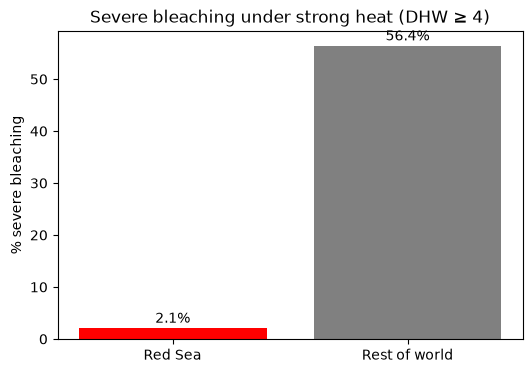

In [215]:
#4- bar chart
plt.figure(figsize=(6, 4))
plt.bar(twist.index, twist["severe_pct"], color=["red", "gray"])
for i, v in enumerate(twist["severe_pct"]):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")   # write the % on top of each bar
plt.title("Severe bleaching under strong heat (DHW ≥ 4)")
plt.ylabel("% severe bleaching")
plt.show()

**What did you learn? (2–3 lines with numbers)**

Answer:
* Under the same strong heat (DHW ≥ 4), only 2.1% of Red Sea samples bleached severely, vs 56.4% in the rest of the world (average bleaching 1.7% vs 36.1%).
* Red Sea corals live in one of the hottest seas on Earth and seem to be used to heat. So while reefs around the world may die, the Red Sea could become a refuge for corals: our Saudi reefs may be one of the world's last coral treasures, and they are worth protecting.
* The Red Sea group is small (94 samples from 33 sites) and mostly from Egypt in the north (87 samples, only 2 from Saudi Arabia). Research agrees that northern Red Sea corals are very heat-tolerant, but corals in the central and southern Red Sea are more sensitive and have bleached in the past. So Jazan (south), which is on severe alert today, may not be protected.


Sources: Osman et al. (2018), Global Change Biology, doi:10.1111/gcb.13895 · Eladawy et al. (2022), Frontiers in Marine Science, doi:10.3389/fmars.2022.938454

---
# 🤿 PART 4 — DIVE & ACT (Member 4)

# Task 7.1 — Dive sites

* Share of sites per country (top 10) → sampling bias?
* Distribution of `visibility` and `fish_species` per survey
* Top 10 sites by average fish species (merge `surveys` with `sites`)

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 7.2 — Rare creatures near dive sites

* Count of threatened species by `category` (CR = critically endangered, EN = endangered, VU = vulnerable)
* The 10 most common threatened species near our dive sites
* Which site has the most CR species?

In [213]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

---
# Task 8 — Summary (everyone)

Write the **5 most important numbers** for our story (one per tab), for example:
```
1 Why care?      -> ...
2 Discover       -> ...
3 Danger         -> ...
4 At Risk        -> ...
5 Dive & Act     -> ...
```

Answer: